# Atmosphere AI | PM2.5 forecasting assessment

Forecast hourly PM2.5 concentrations in µg/m³ for horizons from 1 to 72 hours. Run the notebook with `CAMS-Database-Extract.csv` beside it. Required Python packages: `pandas`, `numpy`, `scikit-learn`, `lightgbm`, `xgboost`, and `matplotlib`.

The notebook trains and evaluates a fresh model on the supplied database extract. The app's October 15 experiment uses its own saved model and evaluation records.

In [1]:
from datetime import timedelta
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 115})
seed = 42
heldout_city = 'nairobi'
source_file = Path('CAMS-Database-Extract.csv')
if not source_file.exists():
    source_file = Path('deliverables/ml-evaluation') / source_file
data = pd.read_csv(source_file)
data['timestamp'] = pd.to_datetime(data['timestamp'], utc=True, format='mixed')
data['retrieved_at'] = pd.to_datetime(data['retrieved_at'], utc=True, format='mixed')
data = data.sort_values(['city_id', 'timestamp']).reset_index(drop=True)

## 1. Dataset quality and justification

Copernicus CAMS atmospheric estimates are provided by Open-Meteo. The hourly cadence matches the forecast target, and the eight cities provide a range of concentration patterns. CAMS supplies atmospheric-model estimates. Station observations would be needed for station-level validation.

Rows: 70,032 | Cities: 8 | Duplicate city-hours: 0
UTC coverage: 2025-10-16 00:00:00+00:00 to 2026-10-15 17:00:00+00:00


,city_id,timestamp,pm25,pm10,no2,o3,so2,co,source
0,cairo,2025-10-16 00:00:00+00:00,28.7,37.8,41.4,38.0,45.8,262.0,Open-Meteo / CAMS
1,cairo,2025-10-16 01:00:00+00:00,28.2,38.5,34.7,37.0,44.8,237.0,Open-Meteo / CAMS
2,cairo,2025-10-16 02:00:00+00:00,30.3,41.1,34.3,34.0,43.8,229.0,Open-Meteo / CAMS
3,cairo,2025-10-16 03:00:00+00:00,32.4,43.8,32.9,26.0,43.8,236.0,Open-Meteo / CAMS
4,cairo,2025-10-16 04:00:00+00:00,34.6,46.7,30.7,26.0,48.2,247.0,Open-Meteo / CAMS
5,cairo,2025-10-16 05:00:00+00:00,32.2,42.3,40.0,30.0,66.6,295.0,Open-Meteo / CAMS


,pm25,pm10,no2,o3,so2,co
Missing values,0,0,0,0,0,0


,Hours,Missing hours,Mean_PM25,P95_PM25
city_id,,,,
cairo,8754,0,23.20,49.30
delhi,8754,0,88.03,188.10
london,8754,0,7.81,18.60
nairobi,8754,0,12.38,23.74
new-york,8754,0,14.31,34.70
sao-paulo,8754,0,19.72,48.90
sydney,8754,0,10.71,23.20
tokyo,8754,0,26.40,63.10


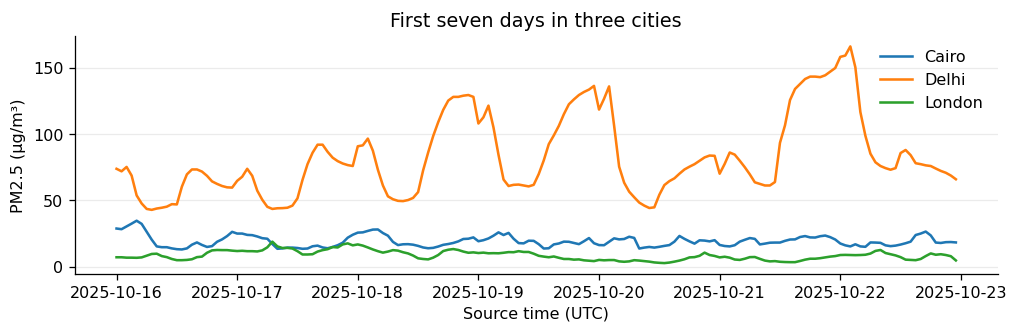

In [2]:
pollutant_columns = ['pm25', 'pm10', 'no2', 'o3', 'so2', 'co']
expected_sources = {'Open-Meteo / CAMS'}
duplicates = int(data.duplicated(['city_id', 'timestamp']).sum())
assert set(data['source']) == expected_sources
assert duplicates == 0
assert data[['timestamp', 'city_id', 'latitude', 'longitude']].notna().all().all()
assert np.isfinite(data[pollutant_columns].dropna().to_numpy()).all()
assert data[pollutant_columns].min().ge(0).all()

print(f"Rows: {len(data):,} | Cities: {data['city_id'].nunique()} | Duplicate city-hours: {duplicates}")
print(f"UTC coverage: {data['timestamp'].min()} to {data['timestamp'].max()}")
display(data[['city_id', 'timestamp', *pollutant_columns, 'source']].head(6))
display(data[pollutant_columns].isna().sum().rename('Missing values').to_frame().T)

coverage = data.groupby('city_id').agg(
    Hours=('timestamp', 'size'), First=('timestamp', 'min'), Last=('timestamp', 'max'),
    Mean_PM25=('pm25', 'mean'), P95_PM25=('pm25', lambda values: values.quantile(.95)),
)
coverage['Missing hours'] = ((coverage['Last'] - coverage['First']) / pd.Timedelta(hours=1) + 1 - coverage['Hours']).astype(int)
display(coverage[['Hours', 'Missing hours', 'Mean_PM25', 'P95_PM25']].round(2))

week_start = data['timestamp'].min()
sample_week = data.loc[data['timestamp'].lt(week_start + pd.Timedelta(days=7))]
fig, ax = plt.subplots(figsize=(9, 3))
for city in ['cairo', 'delhi', 'london']:
    sample = sample_week.loc[sample_week['city_id'].eq(city)]
    ax.plot(sample['timestamp'], sample['pm25'], label=city.title(), linewidth=1.6)
ax.set(title='First seven days in three cities', xlabel='Source time (UTC)', ylabel='PM2.5 (µg/m³)')
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 2. Preprocessing and leakage controls

Each example uses the 73 hourly PM2.5 observations ending at the forecast origin. A gap or missing PM2.5 invalidates the window. Features include pollution lags, trailing statistics, current co-pollutants with missing indicators, geography, target calendar fields, and forecast horizon. Weather is excluded. The label is the PM2.5 estimate at the target hour. Calendar values can be computed before the target hour occurs.

In [3]:
HORIZONS = tuple(range(1, 73))
LAGS = (0, 1, 3, 6, 12, 24, 48, 72)
POLLUTANTS = ('pm25', 'pm10', 'no2', 'o3', 'so2', 'co')

def utc(value):
    value = pd.Timestamp(value)
    return value.tz_localize('UTC') if value.tzinfo is None else value.tz_convert('UTC')

def normalized_history(frame):
    result = frame.copy()
    result['timestamp'] = pd.to_datetime(result['timestamp'], utc=True)
    return result.sort_values('timestamp').drop_duplicates('timestamp', keep='last')

def origin_features(frame, origin):
    origin = utc(origin)
    indexed = normalized_history(frame).set_index('timestamp')
    expected = pd.date_range(origin - timedelta(hours=72), origin, freq='h')
    past = indexed.reindex(expected)
    values = pd.to_numeric(past.pm25, errors='coerce')
    if len(values) != 73 or not np.isfinite(values.to_numpy()).all():
        raise ValueError('73 consecutive hours of nonmissing PM2.5 history are required')
    features = {f'pm25_lag_{lag}': float(values.iloc[-1 - lag]) for lag in LAGS}
    for window in (6, 24, 72):
        recent = values.iloc[-window:]
        for name, value in [('mean', recent.mean()), ('std', recent.std(ddof=0)), ('min', recent.min()), ('max', recent.max())]:
            features[f'pm25_{name}_{window}h'] = float(value)
    features['pm25_trend_6h'] = float(values.iloc[-1] - values.iloc[-7]) / 6
    for pollutant in POLLUTANTS[1:]:
        value = past[pollutant].iloc[-1] if pollutant in past else np.nan
        valid = pd.notna(value) and np.isfinite(float(value))
        features[f'{pollutant}_current'] = float(value) if valid else 0.0
        features[f'{pollutant}_missing'] = float(not valid)
    return features

def target_features(base, origin, horizon, latitude, longitude):
    target = utc(origin) + timedelta(hours=int(horizon))
    return {**base, 'latitude': float(latitude), 'longitude': float(longitude), 'horizon_hours': int(horizon), 'target_hour_sin': np.sin(2 * np.pi * target.hour / 24), 'target_hour_cos': np.cos(2 * np.pi * target.hour / 24), 'target_weekday_sin': np.sin(2 * np.pi * target.dayofweek / 7), 'target_weekday_cos': np.cos(2 * np.pi * target.dayofweek / 7), 'target_year_sin': np.sin(2 * np.pi * target.dayofyear / 365.25), 'target_year_cos': np.cos(2 * np.pi * target.dayofyear / 365.25), 'target_weekend': float(target.dayofweek >= 5)}

In [4]:
def forecast_features(frame, origin, latitude, longitude):
    base = origin_features(frame, origin)
    timestamps = [utc(origin) + timedelta(hours=h) for h in HORIZONS]
    return (pd.DataFrame([target_features(base, origin, h, latitude, longitude) for h in HORIZONS]), timestamps)

def build_examples(frame, origin_stride=12, horizons=HORIZONS):
    result = []
    for city_id, city_frame in frame.groupby('city_id', sort=True):
        city_frame = normalized_history(city_frame)
        indexed = city_frame.set_index('timestamp')
        latitude, longitude = city_frame.iloc[0][['latitude', 'longitude']]
        for origin in city_frame.timestamp.iloc[72:-72:origin_stride]:
            try:
                base = origin_features(city_frame, origin)
            except ValueError:
                continue
            for horizon in horizons:
                target = origin + timedelta(hours=int(horizon))
                if target not in indexed.index or pd.isna(indexed.loc[target, 'pm25']):
                    continue
                seasonal_time = origin + timedelta(hours=(int(horizon) - 1) % 24 - 23)
                seasonal = indexed.loc[seasonal_time, 'pm25']
                result.append({**target_features(base, origin, horizon, latitude, longitude), 'origin': origin, 'target_timestamp': target, 'city_id': city_id, 'target': float(indexed.loc[target, 'pm25']), 'persistence': base['pm25_lag_0'], 'seasonal_naive': float(seasonal)})
    if not result:
        raise ValueError('No complete origin/target windows available; collect at least 30 days')
    return pd.DataFrame(result)
NON_FEATURES = {'origin', 'target_timestamp', 'city_id', 'target', 'persistence', 'seasonal_naive'}

def feature_columns(examples):
    return [c for c in examples.columns if c not in NON_FEATURES]

def temporal_split(examples, validation_start=None, test_start=None):
    origins = examples.origin.sort_values().unique()
    if len(origins) < 20:
        raise ValueError('Too few rolling origins for chronological evaluation')
    validation_start = utc(validation_start) if validation_start is not None else pd.Timestamp(origins[int(len(origins) * 0.65)])
    test_start = utc(test_start) if test_start is not None else pd.Timestamp(origins[int(len(origins) * 0.82)])
    train = examples[examples.origin + timedelta(hours=72) < validation_start]
    validation = examples[(examples.origin >= validation_start) & (examples.origin + timedelta(hours=72) < test_start)]
    test = examples[examples.origin >= test_start]
    if min(len(train), len(validation), len(test)) == 0:
        raise ValueError('Training window too short after 72-hour temporal purging')
    return (train.copy(), validation.copy(), test.copy())

In [5]:
cairo = data.loc[data['city_id'].eq('cairo')].copy()
origin = cairo['timestamp'].iloc[100]
changed = cairo.copy()
changed.loc[changed['timestamp'].gt(origin), pollutant_columns] = 999999.0
assert origin_features(cairo, origin) == origin_features(changed, origin)
assert 'target' not in feature_columns(pd.DataFrame(columns=['target', 'pm25_lag_0']))
print('Future-value perturbation check passed: future pollutant values leave features unchanged.')

training_horizons = (1, 3, 6, 12, 18, 24, 36, 48, 60, 72)
known = data.loc[data['city_id'].ne(heldout_city)]
examples = build_examples(known, origin_stride=23)
training, validation, test = temporal_split(examples)
training = training.loc[training['horizon_hours'].isin(training_horizons)]
heldout_examples = build_examples(data.loc[data['city_id'].eq(heldout_city)], origin_stride=23)
heldout = heldout_examples.loc[heldout_examples['origin'].ge(test['origin'].min())]
schema = feature_columns(training)

assert training['origin'].max() + pd.Timedelta(hours=72) < validation['origin'].min()
assert validation['origin'].max() + pd.Timedelta(hours=72) < test['origin'].min()
assert training['target_timestamp'].max() < validation['origin'].min()
assert validation['target_timestamp'].max() < test['origin'].min()
assert all(heldout_city not in part['city_id'].unique() for part in (training, validation, test))
assert heldout['city_id'].unique().tolist() == [heldout_city]
assert all(set(part['horizon_hours']) == set(HORIZONS) for part in (validation, test, heldout))
assert np.isfinite(training[schema].to_numpy()).all()

def split_summary(part):
    return {'Examples': len(part), 'Cities': part['city_id'].nunique(),
            'First origin (UTC)': part['origin'].min(), 'Last target (UTC)': part['target_timestamp'].max(),
            'Horizons': part['horizon_hours'].nunique()}

display(pd.DataFrame({name: split_summary(part) for name, part in (
    ('Training', training), ('Validation', validation), ('Test', test), ('Nairobi holdout', heldout),
)}).T)
print(f'Feature count: {len(schema)}')
display(training[['city_id', 'origin', 'target_timestamp', 'horizon_hours', 'pm25_lag_0', 'pm25_mean_24h', 'target']].head())

Future-value perturbation check passed: future pollutant values leave features unchanged.


,Examples,Cities,First origin (UTC),Last target (UTC),Horizons
Training,16800,7,2025-10-19 00:00:00+00:00,2026-06-08 01:00:00+00:00,10
Validation,30744,7,2026-06-08 21:00:00+00:00,2026-08-08 09:00:00+00:00,72
Test,34272,7,2026-08-09 05:00:00+00:00,2026-10-15 10:00:00+00:00,72
Nairobi holdout,4896,1,2026-08-09 05:00:00+00:00,2026-10-15 10:00:00+00:00,72


Feature count: 41


,city_id,origin,target_timestamp,horizon_hours,pm25_lag_0,pm25_mean_24h,target
0,cairo,2025-10-19 00:00:00+00:00,2025-10-19 01:00:00+00:00,1,19.1,19.5125,19.9
2,cairo,2025-10-19 00:00:00+00:00,2025-10-19 03:00:00+00:00,3,19.1,19.5125,23.3
5,cairo,2025-10-19 00:00:00+00:00,2025-10-19 06:00:00+00:00,6,19.1,19.5125,25.4
11,cairo,2025-10-19 00:00:00+00:00,2025-10-19 12:00:00+00:00,12,19.1,19.5125,16.9
17,cairo,2025-10-19 00:00:00+00:00,2025-10-19 18:00:00+00:00,18,19.1,19.5125,18.7


The split is chronological. Origins are removed if their 72-hour target window reaches the next period. Nairobi is held out of both fitting and selection. The pooled model fits ten selected horizons and uses the horizon as a feature. Validation, test, and inference cover every hour from 1 through 72. Overlapping windows make the reported example counts dependent.

## 3. Training, model choice, and baselines

Persistence repeats the last available PM2.5 value. Seasonal naive repeats the most recent observed 24-hour cycle. Ridge, Random Forest, LightGBM and XGBoost are fitted on the same training examples. Ridge scaling is fitted inside its training pipeline. The winner is fixed by validation MAE before the test is scored.

In [6]:
def predict(model, frame):
    return np.maximum(0, model.predict(frame[schema]))

ridge_candidates = {
    alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(training[schema], training['target'])
    for alpha in (.1, 10, 100, 1000)
}
ridge_alpha = min(ridge_candidates, key=lambda alpha:
    mean_absolute_error(validation['target'], predict(ridge_candidates[alpha], validation)))

models = {
    'Ridge': ridge_candidates[ridge_alpha],
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=8, n_jobs=4, random_state=seed),
    'LightGBM': LGBMRegressor(n_estimators=280, learning_rate=.05, num_leaves=31, min_child_samples=30,
                           reg_lambda=2, random_state=seed, n_jobs=4, verbosity=-1, deterministic=True, force_col_wise=True),
    'XGBoost': XGBRegressor(n_estimators=280, learning_rate=.05, max_depth=6, min_child_weight=15,
                           subsample=1, colsample_bytree=1, reg_lambda=3, n_jobs=4, random_state=seed,
                           tree_method='hist', objective='reg:squarederror'),
}
baselines = {'Persistence': 'persistence', 'Seasonal naive': 'seasonal_naive'}

started = perf_counter()
for name, model in models.items():
    if name != 'Ridge':
        model.fit(training[schema], training['target'])

def all_predictions(frame):
    return {**{name: predict(model, frame) for name, model in models.items()},
            **{name: frame[column].to_numpy() for name, column in baselines.items()}}

validation_predictions = all_predictions(validation)
validation_mae = pd.Series({name: mean_absolute_error(validation['target'], values)
                            for name, values in validation_predictions.items()})
winner = validation_mae.loc[list(models)].idxmin()
print(f'Selected model: {winner} | Validation MAE: {validation_mae[winner]:.4f} µg/m³ | Ridge alpha: {ridge_alpha}')
print(f'Training and validation completed in {perf_counter() - started:.1f} seconds after fitting Ridge candidates.')
display(validation_mae.sort_values().rename('Validation MAE (µg/m³)').round(4).to_frame())

Selected model: LightGBM | Validation MAE: 10.6625 µg/m³ | Ridge alpha: 1000
Training and validation completed in 6.2 seconds after fitting Ridge candidates.


,Validation MAE (µg/m³)
LightGBM,10.6625
Random Forest,10.7080
XGBoost,10.8610
Ridge,11.3559
Persistence,11.9896
Seasonal naive,12.5872


## 4. Test metrics and interpretation

MAE is the average absolute error in µg/m³. RMSE gives greater weight to large errors and uses the same units. R² describes fit relative to a constant-mean reference. Bias is the average signed error, computed as prediction minus target.

In [7]:
def score(actual, prediction):
    return {'MAE': mean_absolute_error(actual, prediction),
            'RMSE': np.sqrt(mean_squared_error(actual, prediction)),
            'R²': r2_score(actual, prediction),
            'Bias': float(np.mean(prediction - actual))}

test_predictions = all_predictions(test)
test_scores = pd.DataFrame({name: score(test['target'], values) for name, values in test_predictions.items()}).T
leaderboard = test_scores.join(validation_mae.rename('Validation MAE')).sort_values('Validation MAE')
display(leaderboard[['Validation MAE', 'MAE', 'RMSE', 'R²', 'Bias']].round(4))

improvements = {name: 100 * (test_scores.loc[name, 'MAE'] - test_scores.loc[winner, 'MAE']) / test_scores.loc[name, 'MAE']
                for name in baselines}
best_test_model = test_scores.loc[list(models), 'MAE'].idxmin()
display(Markdown(
    f"**Known-city test:** {winner} scored **{test_scores.loc[winner, 'MAE']:.2f} µg/m³ MAE**. "
    f"Its MAE reduction was **{improvements['Persistence']:.2f}%** against persistence and "
    f"**{improvements['Seasonal naive']:.2f}%** against seasonal naive. "
    f"{best_test_model} had the lowest test MAE among fitted models. {winner} was selected on validation."
))

holdout_predictions = {winner: predict(models[winner], heldout),
                       **{name: heldout[column].to_numpy() for name, column in baselines.items()}}
holdout_scores = pd.DataFrame({name: score(heldout['target'], values) for name, values in holdout_predictions.items()}).T
print(f'Nairobi holdout: {len(heldout):,} examples across all 72 horizons')
display(holdout_scores.sort_values('MAE').round(4))
display(Markdown(f"**Transfer check:** {holdout_scores['MAE'].idxmin()} had the lowest MAE in Nairobi. This is evidence from one held-out city."))

,Validation MAE,MAE,RMSE,R²,Bias
LightGBM,10.6625,8.5785,14.3597,0.5902,-0.5399
Random Forest,10.7080,8.9180,14.8993,0.5588,0.6483
XGBoost,10.8610,8.4992,14.2286,0.5977,-0.5711
Ridge,11.3559,9.6246,14.4901,0.5827,1.2669
Persistence,11.9896,10.2690,16.6021,0.4522,-0.3902
Seasonal naive,12.5872,9.9198,16.0395,0.4887,-0.1472


**Known-city test:** LightGBM scored **8.58 µg/m³ MAE**. Its MAE reduction was **16.46%** against persistence and **13.52%** against seasonal naive. XGBoost had the lowest test MAE among fitted models. LightGBM was selected on validation.

Nairobi holdout: 4,896 examples across all 72 horizons


,MAE,RMSE,R²,Bias
Seasonal naive,3.8521,5.3140,-0.0390,0.2039
LightGBM,4.0520,5.0094,0.0767,2.2331
Persistence,4.2572,5.8437,-0.2564,0.7209


**Transfer check:** Seasonal naive had the lowest MAE in Nairobi. This is evidence from one held-out city.

,LightGBM,Persistence,Seasonal naive
city_id,,,
london,2.54,2.85,2.93
cairo,4.03,5.05,4.07
sydney,5.28,6.58,6.77
new-york,6.21,8.69,7.90
tokyo,8.32,10.45,10.14
sao-paulo,10.57,13.29,14.11
delhi,23.09,24.97,23.52


,LightGBM,Persistence,Seasonal naive,Examples
target,,,,
Below 10,4.15,4.92,5.35,10277
10 to <35,6.62,8.61,8.12,18350
35 to <75,20.59,22.36,21.33,3982
75 and above,28.86,32.76,30.65,1663


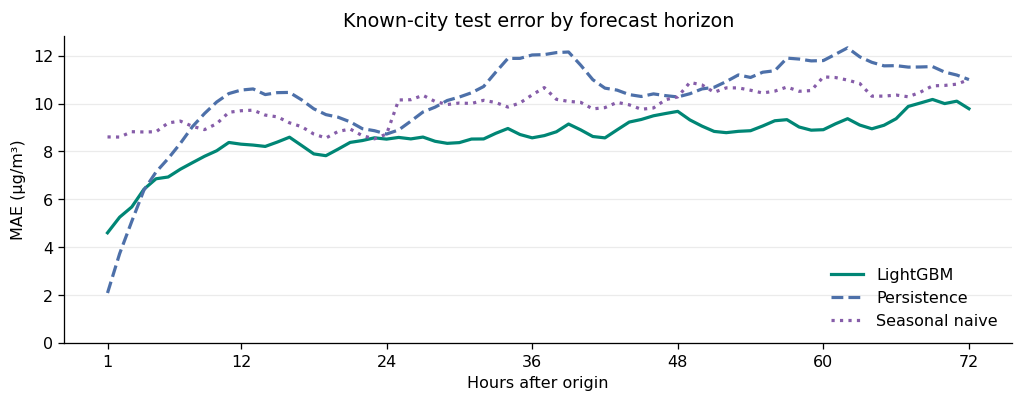

LightGBM's MAE was **4.60 µg/m³** at +1 hour and **9.79 µg/m³** at +72 hours. The highest concentration band had MAE **28.86 µg/m³**. Concentration bands are descriptive groups.

In [8]:
errors = pd.DataFrame({name: np.abs(values - test['target'].to_numpy()) for name, values in test_predictions.items()}, index=test.index)
selected_methods = [winner, *baselines]
by_city = errors[selected_methods].groupby(test['city_id']).mean().sort_values(winner)
by_horizon = errors[selected_methods].groupby(test['horizon_hours']).mean()
band = pd.cut(test['target'], bins=[-np.inf, 10, 35, 75, np.inf],
              labels=['Below 10', '10 to <35', '35 to <75', '75 and above'], right=False)
by_band = errors[selected_methods].groupby(band, observed=True).mean().join(band.value_counts(sort=False).rename('Examples'))
display(by_city.round(2))
display(by_band.round(2))

ax = by_horizon.plot(figsize=(9, 3.6), color=['#008675', '#4d70a9', '#865da9'], style=['-', '--', ':'], linewidth=2)
ax.set(title='Known-city test error by forecast horizon', xlabel='Hours after origin', ylabel='MAE (µg/m³)', ylim=(0, None))
ax.set_xticks([1, 12, 24, 36, 48, 60, 72])
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.25)
ax.figure.tight_layout()
plt.show()

display(Markdown(
    f"{winner}'s MAE was **{by_horizon.loc[1, winner]:.2f} µg/m³** at +1 hour and "
    f"**{by_horizon.loc[72, winner]:.2f} µg/m³** at +72 hours. "
    f"The highest concentration band had MAE **{by_band.loc['75 and above', winner]:.2f} µg/m³**. "
    "Concentration bands are descriptive groups."
))

## 5. A 72-hour forecast from the trained model

The forecast uses one historic Cairo origin from the known-city test period. CAMS target values are joined after prediction for comparison. The retrospective archive records valid times. Original publication delays and revisions are unverified, and prediction intervals have yet to be calibrated.

Cairo historical test origin: 2026-08-09 05:00:00+00:00


,Time (UTC),Horizon (hours),CAMS PM2.5 (µg/m³),Predicted PM2.5 (µg/m³)
0,2026-08-09 06:00:00+00:00,1,21.8,22.84
1,2026-08-09 07:00:00+00:00,2,19.9,22.13
2,2026-08-09 08:00:00+00:00,3,21.0,20.92
3,2026-08-09 09:00:00+00:00,4,20.2,20.08
4,2026-08-09 10:00:00+00:00,5,21.5,19.93
5,2026-08-09 11:00:00+00:00,6,20.9,18.55


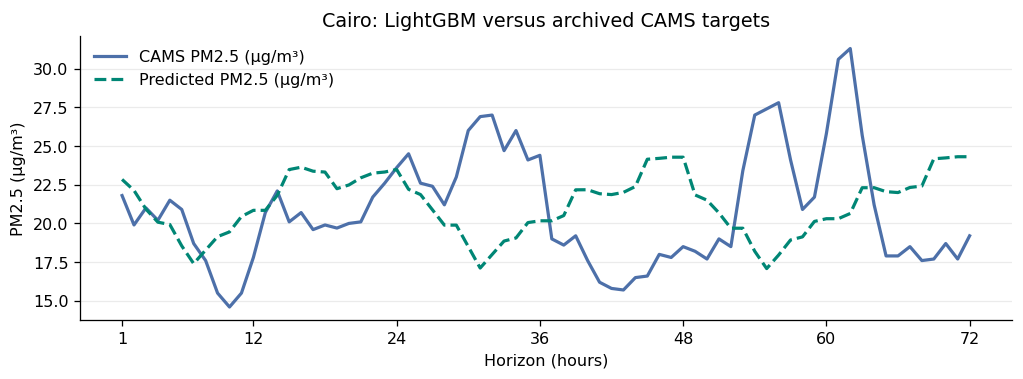

In [9]:
cairo_test = test.loc[test['city_id'].eq('cairo')]
demo_origin = cairo_test['origin'].min()
demo_targets = cairo_test.loc[cairo_test['origin'].eq(demo_origin)].sort_values('horizon_hours')
latitude, longitude = cairo.iloc[0][['latitude', 'longitude']]
demo_features, timestamps = forecast_features(cairo, demo_origin, latitude, longitude)
demo_prediction = predict(models[winner], demo_features)
assert len(demo_prediction) == 72 and np.isfinite(demo_prediction).all()
assert list(demo_targets['target_timestamp']) == timestamps
assert np.allclose(demo_prediction, test_predictions[winner][test.index.get_indexer(demo_targets.index)])

demo = pd.DataFrame({'Time (UTC)': timestamps, 'Horizon (hours)': HORIZONS,
                     'CAMS PM2.5 (µg/m³)': demo_targets['target'].to_numpy(),
                     'Predicted PM2.5 (µg/m³)': demo_prediction})
print(f'Cairo historical test origin: {demo_origin}')
display(demo.head(6).round({'CAMS PM2.5 (µg/m³)': 2, 'Predicted PM2.5 (µg/m³)': 2}))
ax = demo.set_index('Horizon (hours)').drop(columns='Time (UTC)').plot(
    figsize=(9, 3.4), color=['#4d70a9', '#008675'], style=['-', '--'], linewidth=2,
)
ax.set(title=f'Cairo: {winner} versus archived CAMS targets', ylabel='PM2.5 (µg/m³)')
ax.set_xticks([1, 12, 24, 36, 48, 60, 72])
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.25)
ax.figure.tight_layout()
plt.show()

## 6. UI/UX assessment evidence

| Assessment item | Where to demonstrate it |
| --- | --- |
| Main user flow | Overview → choose a city → City intelligence → Forecast studio → Comparison. Data explorer and Model intelligence show the underlying evidence. |
| Consistent navigation and design | The eight screens share navigation, chart conventions, and unit labels. |
| Responsive planning | Compact navigation and stacked content for narrow screens. The project records a 390 px mobile browser check. |
| Clear input and results | City, pollutant and period controls lead to charts and tables with units and timestamps. Forecast studio distinguishes historic estimates and predicted values. |
| Validation and error states | Comparison prompts for at least two cities and supports up to five. Forecast errors identify unsupported locations or missing history. Query panels distinguish loading, errors with retry, and no results. |

[Arabic screen guide](../app-screenshots/Atmosphere-AI-Screen-Guide-AR.pdf) · [Screenshots only](../app-screenshots/Atmosphere-AI-Screenshots-Only.pdf) · [Project implementation and mobile test record](../../docs/IMPLEMENTATION_STATUS.md)